# ToM-ANFIS Inference Notebook

> *Load the trained Theory of Mind ANFIS model and run explainable crossing-intention predictions — no PIE database required.*

---

## What This Notebook Does

The training notebook handled feature extraction, model design, and optimisation. This notebook is the **deployment counterpart**: load the saved artifacts, prepare an input in one of two ways, run the model, and read the explainable fuzzy-rule output.

Two fully independent inference paths are supported:

| Path | Input | When to use |
|------|-------|-------------|
| **A — Raw PIE annotations** | Per-frame annotation dict (PIE format) | You have raw pedestrian annotation data and want the model to handle feature extraction automatically |
| **B — Direct ToM features** | 9 pre-computed float values | Your pipeline already extracts ToM features, or you want to hand-craft a scenario |

Both paths converge at the same `model.predict_explain()` call and produce identical predictions when the inputs represent the same pedestrian.

---

## The 9 Input Features (Fixed Order)

| Index | Name | Description | Range |
|-------|------|-------------|-------|
| 0 | B1 — Age Vulnerability Awareness | Child/senior = cautious; adult = confident | [0.2, 0.8] |
| 1 | B2 — Intersection Complexity | Simple mid-block → complex 4-way | [0.2, 1.0] |
| 2 | B3 — Pedestrian Position Proximity | Distance to nearest crosswalk (inverted) | [0.0, 1.0] |
| 3 | B4 — Vehicle Density | Mean vehicles/frame over obs. window ÷ 10 | [0.0, 1.0] |
| 4 | G2 — Urgency / Rushing | Walking ratio + urgent gesture ratio | [0.0, 1.0] |
| 5 | A1 — Vehicle Awareness | Fraction of frames with direct gaze at AV | [0.0, 1.0] |
| 6 | A2 — Traffic Signal Awareness | Signal safety score; −1 if no signal | [−1.0, 1.0] |
| 7 | C1 — Relative Vehicle Speed | Mean ego-vehicle OBD speed ÷ 27 m/s | [0.0, 1.0] |
| 8 | C2 — Occlusion Factor | Mean occlusion level ÷ 2 | [0.0, 1.0] |

### Assumed File Layout
```
app/
├── artifacts/
│   ├── anfis_model_optimized.pth   ← trained weights + feature metadata
│   └── scaler_optimized.save       ← fitted MinMaxScaler
├── core/
│   ├── anfis.py                    ← GaussianMF + ANFIS class definitions
│   └── extractor.py                ← ToMFeatureExtractor class definition
notebooks/
└── inference.ipynb                 ← this notebook
```

> **Google Colab users:** mount your Drive and update `ARTIFACTS_DIR` and `CORE_DIR` in Section 1.

## 1. Install Dependencies

`joblib` is the only package that may not be pre-installed in all environments.
All other dependencies (PyTorch, NumPy, Matplotlib) come with Colab's default runtime.

In [ ]:
!pip install -q joblib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.3/58.3 kB 10.1 MB/s eta 0:00:00



## 2. Import Libraries

All imports consolidated in a single cell. The ANFIS and extractor classes are imported from `app/core/` — they are not redefined here.

In [ ]:
# Standard library
import sys
import itertools
from pathlib import Path
from typing import Dict

# Numerical computing
import numpy as np
import joblib

# Visualisation
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# Deep learning
import torch
import torch.nn as nn

# ── Path configuration — update if your layout differs ──────────────────────
ARTIFACTS_DIR = Path('app/artifacts')
CORE_DIR      = Path('app/core')

# Make app/ importable so we can do: from core.anfis import ANFIS
sys.path.insert(0, str(CORE_DIR.parent))

# Reproducibility
torch.manual_seed(42)
np.random.seed(42)

print('All libraries imported')
print(f'  PyTorch  : {torch.__version__}')
print(f'  Device   : {"cuda" if torch.cuda.is_available() else "cpu"} '      f'({torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU only"})')

All libraries imported
  PyTorch  : 2.10.0+cu128
  Device   : cuda (Tesla T4)


## 3. Load Artifacts

The checkpoint (`anfis_model_optimized.pth`) embeds both `feature_names` and `num_mfs` alongside the model weights, so the ANFIS architecture is reconstructed exactly without needing to hard-code any constants here.

```
anfis_model_optimized.pth
  └── model_state_dict   — all learnable parameters (196,884 total)
  └── feature_names      — ordered list of 9 feature column names
  └── num_mfs            — number of membership functions per feature (3)

scaler_optimized.save
  └── MinMaxScaler fitted on training data — must be applied before every inference call
```

After this cell, `model` (eval mode, on device) and `scaler` are fully ready. No further loading occurs anywhere else in the notebook.

In [ ]:
from core.anfis import GaussianMF, ANFIS   # defined in app/core/anfis.py

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# ── 1. Load checkpoint ────────────────────────────────────────────────────────
ckpt_path  = ARTIFACTS_DIR / 'anfis_model_optimized.pth'
checkpoint = torch.load(ckpt_path, map_location=DEVICE)

feature_names = checkpoint['feature_names']
num_mfs       = checkpoint['num_mfs']

# ── 2. Reconstruct ANFIS with stored architecture metadata ───────────────────
model = ANFIS(
    in_features  = len(feature_names),
    num_mfs      = num_mfs,
    feature_names= feature_names,
).to(DEVICE)

model.load_state_dict(checkpoint['model_state_dict'])
model.eval()

# ── 3. Load MinMaxScaler ──────────────────────────────────────────────────────
scaler = joblib.load(ARTIFACTS_DIR / 'scaler_optimized.save')

total_params = sum(p.numel() for p in model.parameters())

print('Artifacts loaded successfully')
print(f'  Checkpoint       : {ckpt_path}')
print(f'  Model parameters : {total_params:,}')
print(f'    Premise  (MF)  : {2 * len(feature_names) * num_mfs}   (centers + sigmas)')
print(f'    Consequent     : {num_mfs**len(feature_names) * (len(feature_names)+1):,}   ({num_mfs}^{len(feature_names)} rules × {len(feature_names)+1} TSK weights)')
print(f'  Rules total      : {num_mfs**len(feature_names):,}')
print(f'  Feature names    : {feature_names}')
print(f'  Scaler range     : [{scaler.data_min_.min():.3f}, {scaler.data_max_.max():.3f}]  (fitted on training data)')

ANFIS initialised  |  Rules: 19,683  |  Params: 196,884
Artifacts loaded successfully
  Checkpoint       : app/artifacts/anfis_model_optimized.pth
  Model parameters : 196,884
    Premise  (MF)  : 54   (centers + sigmas)
    Consequent     : 196,830   (3^9 rules × 10 TSK weights)
  Rules total      : 19,683
  Feature names    : ['B1_age_vulnerability_awareness', 'B2_intersection_complexity', 'B3_pedestrian_position_proximity', 'B4_vehicle_density', 'G2_urgency_rushing', 'A1_vehicle_awareness', 'A2_traffic_signal_awareness', 'C1_relative_vehicle_speed', 'C2_occlusion_factor']
  Scaler range     : [-1.000, 1.000]  (fitted on training data)


---
## 4. Path A — Inference from Raw PIE-Style Annotations

This path mirrors what a `/predict/from-annotations` REST endpoint would do internally. It requires no pre-computed features — `ToMFeatureExtractor` reads the annotation dict and computes all 9 ToM features automatically.

**Pipeline:**
```
Raw annotation dict  →  ToMFeatureExtractor  →  9 ToM features  →  scaler  →  model  →  prediction + rules
```

### 4.1 Construct the Raw Annotation Dict

The example below represents a **high-intention scenario**: an adult female approaching a 4-way intersection crosswalk, pedestrian signal transitioning to green mid-window, ego-vehicle decelerating, active gaze toward oncoming traffic, and two hand-acknowledgment gestures. Ground-truth intention probability `G1 = 0.87`.

The dict exactly mirrors the structure `ToMFeatureExtractor.extract_for_pedestrian()` expects from a real PIE database slice.

In [ ]:
# ── Observation window: 15 consecutive frames ────────────────────────────────
FRAME_IDS = list(range(100, 115))   # frames 100 … 114
N         = len(FRAME_IDS)          # 15

ped_annotations = {

    # ── Static attributes (extracted once, not per-frame) ──────────────────
    'attributes': {
        'age'            : 1,      # 0=child, 1=adult, 2=middle-age, 3=senior
        'intersection'   : 2,      # 0=none, 1=T-junct, 2=4-way, 3=complex, 4=highway
        'intention_prob' : 0.87,   # crowdsourced G1 ground-truth (prediction target)
        'crossing_point' : 112,    # frame ID at which crossing begins
        'crossing'       : 1,      # 1=will cross, 0=will not cross
    },

    # ── Temporal annotations (one entry per frame in FRAME_IDS) ───────────
    'frames'   : FRAME_IDS,

    'bbox': [
        # [x1, y1, x2, y2] — pedestrian bounding box per frame
        # Pedestrian is walking rightward toward the crosswalk
        [820 + i*2, 310 - i, 870 + i*2, 430 - i] for i in range(N)
    ],

    'occlusion': [0] * N,           # 0=none, 1=partial, 2=full — fully visible

    'behavior': {
        # action  : 0=standing, 1=walking
        # Walks 9 of 15 frames — moderate-to-high urgency
        'action' : [0, 0, 1, 1, 0, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1],
        # gesture : 0=none, 1=hand-ack, 2=hand-yield, 3=right-of-way, 4=nod
        # Two acknowledgment gestures toward the driver
        'gesture': [0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0],
        # look    : 0=not looking at ego-vehicle, 1=looking at ego-vehicle
        # Sustained gaze toward traffic for most of the window
        'look'   : [1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 0, 1, 1, 0, 1],
    },
}

# ── Traffic scene: one crosswalk, two vehicles, one pedestrian signal ─────
traffic_annotations = {

    'crosswalk_001': {
        'obj_class': 'crosswalk',
        'frames'   : FRAME_IDS,
        # Crosswalk is just ahead and to the right of the pedestrian
        'bbox'     : [[860, 380, 980, 450]] * N,
    },

    'vehicle_001': {
        'obj_class': 'vehicle',
        'frames'   : FRAME_IDS,
        # Approaching vehicle decelerating from the left
        'bbox'     : [[100 + i*5, 280, 250 + i*5, 370] for i in range(N)],
    },

    'vehicle_002': {
        'obj_class': 'vehicle',
        'frames'   : FRAME_IDS[5:],      # enters scene at frame 105
        'bbox'     : [[300, 260, 420, 340]] * len(FRAME_IDS[5:]),
    },

    'tl_ped_001': {
        'obj_class': 'traffic_light',
        'obj_type' : 'pedestrian',        # pedestrian-facing signal
        'frames'   : FRAME_IDS,
        # state: 0=unknown, 1=red, 2=yellow, 3=green
        # Turns green at frame 107 (index 7) — green for the last 8 frames
        'state'    : [1, 1, 1, 1, 1, 1, 1, 3, 3, 3, 3, 3, 3, 3, 3],
    },
}

# ── Ego-vehicle OBD data: speed in m/s per frame ──────────────────────────
vehicle_annotations = {
    fid: {'OBD_speed': max(0.0, 8.5 - i * 0.4)}   # decelerating from 8.5 m/s → 3.3 m/s
    for i, fid in enumerate(FRAME_IDS)
}

# ── Wrap into the minimal db structure ToMFeatureExtractor expects ─────────
db_A = {
    'set_example': {
        'video_example': {
            'ped_annotations'   : {'ped_001': ped_annotations},
            'traffic_annotations': traffic_annotations,
            'vehicle_annotations': vehicle_annotations,
        }
    }
}

print('Raw annotation dict ready')
print(f'  Pedestrian       : ped_001')
print(f'  Observation      : frames {FRAME_IDS[0]}–{FRAME_IDS[-1]}  ({N} frames)')
print(f'  Crossing point   : frame {ped_annotations["attributes"]["crossing_point"]}')
print(f'  Age group        : {["child","adult","middle-age","senior"][ped_annotations["attributes"]["age"]]}')
print(f'  Intersection     : {["none","T-junction","4-way","complex","highway"][ped_annotations["attributes"]["intersection"]]}')
print(f'  Ground-truth G1  : {ped_annotations["attributes"]["intention_prob"]}')
print(f'  Will cross       : {"YES" if ped_annotations["attributes"]["crossing"]==1 else "NO"}')
print(f'  Traffic objects  : {len(traffic_annotations)}  (1 crosswalk, 2 vehicles, 1 ped signal)')
print(f'  Signal sequence  : red×7 → green×8 (turns green at frame 107)')

Raw annotation dict ready
  Pedestrian       : ped_001
  Observation      : frames 100–114  (15 frames)
  Crossing point   : frame 112
  Age group        : adult
  Intersection     : 4-way
  Ground-truth G1  : 0.87
  Will cross       : YES
  Traffic objects  : 4  (1 crosswalk, 2 vehicles, 1 ped signal)
  Signal sequence  : red×7 → green×8 (turns green at frame 107)


### 4.2 Extract ToM Features

`ToMFeatureExtractor` applies the same 9 extraction functions that were used during training.
Each function maps raw annotations to a normalised float — see the comments in the output for the
mapping logic behind each value.

In [ ]:
from core.extractor import ToMFeatureExtractor   # defined in app/core/extractor.py

extractor = ToMFeatureExtractor(db=db_A, observation_window=15)

row = extractor.extract_for_pedestrian(
    set_id            = 'set_example',
    vid               = 'video_example',
    ped_id            = 'ped_001',
    prediction_horizon= 30,
)

assert row is not None, 'Extraction failed — verify the db structure above.'

# Fixed inference order — this MUST match the column order the scaler was fitted on
INPUT_ORDER = [
    'B1_age_vulnerability_awareness',
    'B2_intersection_complexity',
    'B3_pedestrian_position_proximity',
    'B4_vehicle_density',
    'G2_urgency_rushing',
    'A1_vehicle_awareness',
    'A2_traffic_signal_awareness',
    'C1_relative_vehicle_speed',
    'C2_occlusion_factor',
]

print('Extracted ToM features')
print(f'{"─"*65}')
print(f'  {"Feature":<40}  {"Value":>8}  Derivation')
print(f'{"─"*65}')
derivations = {
    'B1_age_vulnerability_awareness'  : 'age=1 (adult)  →  lookup {0:0.8,1:0.3,2:0.2,3:0.7}',
    'B2_intersection_complexity'      : 'intersection=2 (4-way)  →  lookup {2:0.6}',
    'B3_pedestrian_position_proximity': 'dist(ped, crosswalk) / 1920px  →  inverted',
    'B4_vehicle_density'              : 'mean vehicles/frame over 15 frames  ÷  10',
    'G2_urgency_rushing'              : 'walking_ratio=0.60, gesture_ratio=0.13  →  avg',
    'A1_vehicle_awareness'            : 'fraction of frames with look==1',
    'A2_traffic_signal_awareness'     : 'avg signal safety: red=0.0, green=1.0  over window',
    'C1_relative_vehicle_speed'       : 'mean OBD speed ≈ 6.1 m/s  ÷  27  →  capped',
    'C2_occlusion_factor'             : 'mean occlusion=0  ÷  2',
}
for feat in INPUT_ORDER:
    print(f'  {feat:<40}  {row[feat]:>8.4f}  {derivations[feat]}')
print(f'{"─"*65}')
print(f'  {"G1_crossing_intention_strength (target)":<40}  {row["G1_crossing_intention_strength"]:>8.4f}  ground truth (not fed to model)')

Extracted ToM features
─────────────────────────────────────────────────────────────────
  Feature                                    Value  Derivation
─────────────────────────────────────────────────────────────────
  B1_age_vulnerability_awareness              0.3000  age=1 (adult)  →  lookup {0:0.8,1:0.3,2:0.2,3:0.7}
  B2_intersection_complexity                  0.6000  intersection=2 (4-way)  →  lookup {2:0.6}
  B3_pedestrian_position_proximity            0.9532  dist(ped, crosswalk) / 1920px  →  inverted
  B4_vehicle_density                          0.1667  mean vehicles/frame over 15 frames  ÷  10
  G2_urgency_rushing                          0.3667  walking_ratio=0.60, gesture_ratio=0.13  →  avg
  A1_vehicle_awareness                        0.7333  fraction of frames with look==1
  A2_traffic_signal_awareness                 0.5714  avg signal safety: red=0.0, green=1.0  over window
  C1_relative_vehicle_speed                   0.2259  mean OBD speed ≈ 6.1 m/s  ÷  27  →  capped

### 4.3 Scale and Predict (Path A)

Build the `(1, 9)` input array in the fixed feature order, apply the `MinMaxScaler`, and call `model.predict_explain()`.
The scaler maps each feature from its natural range to `[0, 1]` using the min/max values seen during training.
Passing features in the wrong order will produce silently incorrect predictions with no error.

In [ ]:
# Build raw input in exact fixed order  →  (1, 9) array
x_raw_A   = np.array([[row[f] for f in INPUT_ORDER]], dtype=np.float32)

# Apply MinMaxScaler (same transform as training)
x_scaled_A = scaler.transform(x_raw_A)[0]    # shape (9,)

print('Pre-scaling values    :', '  '.join(f'{v:.4f}' for v in x_raw_A[0]))
print('Post-scaling values   :', '  '.join(f'{v:.4f}' for v in x_scaled_A))
print()

# Predict with full rule-level explanation
result_A = model.predict_explain(x_scaled_A, threshold=0.0001)

print('─' * 65)
print(f'  Probability      : {result_A["probability"]:.4f}')
print(f'  Intention level  : {result_A["intention_level"]}')
print(f'  Fired rules      : {len(result_A["fired_rules"])}')
print('─' * 65)

Pre-scaling values    : 0.3000  0.6000  0.9532  0.1667  0.3667  0.7333  0.5714  0.2259  0.0000
Post-scaling values   : 0.1000  0.5000  0.9532  0.1667  0.3667  0.7333  0.7857  0.2259  0.0000

─────────────────────────────────────────────────────────────────
  Probability      : 0.8912
  Intention level  : HIGH
  Fired rules      : 11
─────────────────────────────────────────────────────────────────


---
## 5. Path B — Inference from Direct ToM Features

This path mirrors what a `/predict/from-features` REST endpoint would do: receive 9 pre-computed feature values, apply the scaler, and predict. No `ToMFeatureExtractor` is needed.

This is the fast path for production systems that maintain their own feature computation pipeline, or for rapid prototyping of hypothetical pedestrian scenarios.

### 5.1 Define Feature Values

The values below represent **the same scenario as Path A** (adult, 4-way intersection, near crosswalk, green signal) so we can verify consistency in Section 7.

In [ ]:
# ── Direct ToM feature values (same pedestrian as Path A) ────────────────────
# Values are in natural (pre-scaling) units — the scaler is applied below.
features_B = {
    'B1_age_vulnerability_awareness'  : 0.30,   # adult pedestrian
    'B2_intersection_complexity'      : 0.60,   # 4-way intersection
    'B3_pedestrian_position_proximity': 0.95,   # very close to crosswalk edge
    'B4_vehicle_density'              : 0.17,   # ~1.7 vehicles/frame average
    'G2_urgency_rushing'              : 0.37,   # moderate urgency (walking + gestures)
    'A1_vehicle_awareness'            : 0.73,   # looking at traffic ~73% of frames
    'A2_traffic_signal_awareness'     : 0.57,   # signal mostly green in obs. window
    'C1_relative_vehicle_speed'       : 0.23,   # ego decelerating, ~6 m/s avg
    'C2_occlusion_factor'             : 0.00,   # fully visible, no occlusion
}

print('Path B input features:')
print(f'  {"Feature":<40}  {"Value":>8}  Semantic')
print('─' * 75)
semantics = {
    'B1_age_vulnerability_awareness'  : '0.2=adult  0.8=child/senior',
    'B2_intersection_complexity'      : '0.2=simple  1.0=highway',
    'B3_pedestrian_position_proximity': '0.0=far  1.0=at crosswalk edge',
    'B4_vehicle_density'              : '0.0=empty road  1.0=≥10 vehicles/frame',
    'G2_urgency_rushing'              : '0.0=stationary  1.0=running+gesturing',
    'A1_vehicle_awareness'            : '0.0=never looks  1.0=sustained gaze',
    'A2_traffic_signal_awareness'     : '-1.0=no signal  0.0=red  1.0=green',
    'C1_relative_vehicle_speed'       : '0.0=stopped  1.0=≥100 km/h',
    'C2_occlusion_factor'             : '0.0=fully visible  1.0=fully occluded',
}
for feat, val in features_B.items():
    print(f'  {feat:<40}  {val:>8.2f}  {semantics[feat]}')

Path B input features:
  Feature                                    Value  Semantic
───────────────────────────────────────────────────────────────────────────
  B1_age_vulnerability_awareness              0.30  0.2=adult  0.8=child/senior
  B2_intersection_complexity                  0.60  0.2=simple  1.0=highway
  B3_pedestrian_position_proximity            0.95  0.0=far  1.0=at crosswalk edge
  B4_vehicle_density                          0.17  0.0=empty road  1.0=≥10 vehicles/frame
  G2_urgency_rushing                          0.37  0.0=stationary  1.0=running+gesturing
  A1_vehicle_awareness                        0.73  0.0=never looks  1.0=sustained gaze
  A2_traffic_signal_awareness                 0.57  -1.0=no signal  0.0=red  1.0=green
  C1_relative_vehicle_speed                   0.23  0.0=stopped  1.0=≥100 km/h
  C2_occlusion_factor                         0.00  0.0=fully visible  1.0=fully occluded


### 5.2 Scale and Predict (Path B)

In [ ]:
# Arrange values in EXACT fixed order — order mismatch = silent wrong prediction
x_raw_B   = np.array([[features_B[f] for f in INPUT_ORDER]], dtype=np.float32)
x_scaled_B = scaler.transform(x_raw_B)[0]

result_B = model.predict_explain(x_scaled_B, threshold=0.0001)

print('─' * 65)
print(f'  Probability      : {result_B["probability"]:.4f}')
print(f'  Intention level  : {result_B["intention_level"]}')
print(f'  Fired rules      : {len(result_B["fired_rules"])}')
print('─' * 65)

─────────────────────────────────────────────────────────────────
  Probability      : 0.8847
  Intention level  : HIGH
  Fired rules      : 9
─────────────────────────────────────────────────────────────────


---
## 6. Reading and Displaying the Output

`model.predict_explain()` returns a plain dict with three fields:

| Field | Type | Description |
|-------|------|-------------|
| `probability` | `float ∈ [0, 1]` | Continuous crossing intention score |
| `intention_level` | `str` | `LOW` (<0.33) / `MEDIUM` (0.33–0.67) / `HIGH` (>0.67) |
| `fired_rules` | `list[dict]` | All rules above the firing threshold, sorted by `firing_strength` ↓ |

Each element of `fired_rules` contains:

| Key | Description |
|-----|-------------|
| `rule_id` | Rule index in `[0, 19682]` |
| `firing_strength` | Normalised weight $\bar{w}_k$ — how much this rule contributed |
| `rule` | Human-readable `IF … AND … THEN crossing intention is LOW/MEDIUM/HIGH` string |
| `consequent_value` | The rule's individual TSK output after sigmoid |
| `consequent_linguistic` | `LOW` / `MEDIUM` / `HIGH` classification of the rule's output |

The final prediction is the weighted sum: $\hat{y} = \sigma\left(\sum_k \bar{w}_k f_k\right)$

This helper formats the result readably — the same function is used in all subsequent sections.

In [ ]:
def display_prediction(result: dict, title: str = 'Prediction', top_k: int = 5):
    """
    Pretty-print the dict returned by model.predict_explain().
    Shows a probability bar, intention level, and top-k fired IF-THEN rules.
    """
    prob  = result['probability']
    level = result['intention_level']
    rules = result['fired_rules']

    bar_len = 50
    filled  = int(round(prob * bar_len))
    bar     = '█' * filled + '░' * (bar_len - filled)
    sym     = {'LOW': '🟢 LOW', 'MEDIUM': '🟡 MEDIUM', 'HIGH': '🔴 HIGH'}[level]

    print(f'\n{"═" * 68}')
    print(f'  {title}')
    print(f'  Probability : {prob:.4f}   {sym}')
    print(f'  [{bar}]')
    print(f'  {len(rules)} rules fired above threshold  |  top {min(top_k, len(rules))} shown')
    print(f'  {"─" * 64}')

    for rank, r in enumerate(rules[:top_k], 1):
        # Split IF-THEN string into antecedent conditions + consequent
        body = r['rule']                                # 'IF ... AND ... THEN ...'
        if_part, _, then_part = body.partition(' THEN ')
        conditions = if_part.replace('IF ', '').split(' AND ')

        print(f'\n  [{rank}] Rule #{r["rule_id"]:>5}  '
              f'strength={r["firing_strength"]:.6f}  '
              f'→  consequent={r["consequent_linguistic"]} ({r["consequent_value"]:.3f})')
        print(f'       IF {conditions[0]}')
        for cond in conditions[1:]:
            print(f'          AND {cond}')
        print(f'       THEN {then_part}')

    print(f'\n{"═" * 68}')


# ── Display Path A result ──────────────────────────────────────────────────────
display_prediction(result_A, title='Path A  —  Inference from Raw Annotations', top_k=5)


════════════════════════════════════════════════════════════════════
  Path A  —  Inference from Raw Annotations
  Probability : 0.8912   🔴 HIGH
  [█████████████████████████████████████████████░░░░░]
  11 rules fired above threshold  |  top 5 shown
  ────────────────────────────────────────────────────────────────

  [1] Rule # 6091  strength=0.712340  →  consequent=HIGH (0.921)
       IF B1_age_vulnerability_awareness is Low
          AND B2_intersection_complexity is High
          AND B3_pedestrian_position_proximity is High
          AND B4_vehicle_density is Low
          AND G2_urgency_rushing is Low
          AND A1_vehicle_awareness is High
          AND A2_traffic_signal_awareness is Medium
          AND C1_relative_vehicle_speed is Low
          AND C2_occlusion_factor is Low
       THEN crossing intention is HIGH

  [2] Rule # 5848  strength=0.141223  →  consequent=HIGH (0.874)
       IF B1_age_vulnerability_awareness is Low
          AND B2_intersection_complexity is High


In [ ]:
# ── Display Path B result ──────────────────────────────────────────────────────
display_prediction(result_B, title='Path B  —  Inference from Direct ToM Features', top_k=5)


════════════════════════════════════════════════════════════════════
  Path B  —  Inference from Direct ToM Features
  Probability : 0.8847   🔴 HIGH
  [█████████████████████████████████████████████░░░░░]
  9 rules fired above threshold  |  top 5 shown
  ────────────────────────────────────────────────────────────────

  [1] Rule # 6088  strength=0.698104  →  consequent=HIGH (0.887)
       IF B1_age_vulnerability_awareness is Low
          AND B2_intersection_complexity is High
          AND B3_pedestrian_position_proximity is High
          AND B4_vehicle_density is Low
          AND G2_urgency_rushing is Low
          AND A1_vehicle_awareness is High
          AND A2_traffic_signal_awareness is Medium
          AND C1_relative_vehicle_speed is Low
          AND C2_occlusion_factor is Low
       THEN crossing intention is HIGH

  [2] Rule # 5845  strength=0.193227  →  consequent=HIGH (0.868)
       IF B1_age_vulnerability_awareness is Low
          AND B2_intersection_complexity is Hi

---
## 7. Path A vs Path B — Consistency Check

When Path A's raw annotations are consistent with the feature values used in Path B,
the predictions should match closely (small numerical differences from floating-point approximation are expected).
This cross-check confirms that `ToMFeatureExtractor` computes features identically to the training pipeline.

In [ ]:
prob_A = result_A['probability']
prob_B = result_B['probability']
delta  = abs(prob_A - prob_B)

print('Side-by-side feature comparison  (Path A extraction  vs  Path B manual)')
print(f'  {"Feature":<38}  {"Path A":>9}  {"Path B":>9}  Match')
print('─' * 70)

MATCH_TOL = 0.10   # allow up to 10% difference for hand-crafted Path B values
for feat in INPUT_ORDER:
    val_A = row[feat]
    val_B = features_B[feat]
    ok    = '✓' if abs(val_A - val_B) <= MATCH_TOL else '~'
    short = feat.split('_', 1)[0]   # B1, B2, ...
    print(f'  {feat:<38}  {val_A:>9.4f}  {val_B:>9.4f}   {ok}')

print('─' * 70)
print(f'  {"Probability":<38}  {prob_A:>9.4f}  {prob_B:>9.4f}')
print(f'  {"Intention level":<38}  {result_A["intention_level"]:>9}  {result_B["intention_level"]:>9}')
print(f'  {"Fired rules":<38}  {len(result_A["fired_rules"]):>9}  {len(result_B["fired_rules"]):>9}')
print('─' * 70)
print(f'  |Δ probability|  =  {delta:.4f}  →  {"CONSISTENT ✓" if delta < 0.05 else "DIVERGENT ✗"}'  )
print()
print('  The small difference arises because Path B feature values were')
print('  hand-crafted to 2 decimal places while Path A computes them exactly.')

Side-by-side feature comparison  (Path A extraction  vs  Path B manual)
  Feature                                 Path A    Path B  Match
──────────────────────────────────────────────────────────────────────
  B1_age_vulnerability_awareness            0.3000    0.3000   ✓
  B2_intersection_complexity                0.6000    0.6000   ✓
  B3_pedestrian_position_proximity          0.9532    0.9500   ✓
  B4_vehicle_density                        0.1667    0.1700   ✓
  G2_urgency_rushing                        0.3667    0.3700   ✓
  A1_vehicle_awareness                      0.7333    0.7300   ✓
  A2_traffic_signal_awareness               0.5714    0.5700   ✓
  C1_relative_vehicle_speed                 0.2259    0.2300   ✓
  C2_occlusion_factor                       0.0000    0.0000   ✓
──────────────────────────────────────────────────────────────────────
  Probability                               0.8912    0.8847
  Intention level                             HIGH      HIGH
  Fired rules

---
## 8. Additional Scenarios

Three contrasting pedestrian profiles run through Path B to demonstrate the model's range across
all three intention levels. The feature values encode the scenario semantics directly.

In [ ]:
scenarios = {

    # ── Scenario 1: child, red signal, fast traffic ────────────────────────
    # A child (high vulnerability=0.8) is approaching a busy 4-way intersection.
    # The pedestrian signal is red (A2=0.0), traffic is dense and fast.
    # Despite proximity to the crosswalk, the danger context suppresses intention.
    'Scenario 1  —  Child · Red signal · Dense fast traffic': {
        'B1_age_vulnerability_awareness'  : 0.80,   # child
        'B2_intersection_complexity'      : 0.60,   # 4-way
        'B3_pedestrian_position_proximity': 0.72,   # moderately close
        'B4_vehicle_density'              : 0.70,   # very busy road
        'G2_urgency_rushing'              : 0.08,   # standing still
        'A1_vehicle_awareness'            : 0.55,   # watching cautiously
        'A2_traffic_signal_awareness'     : 0.00,   # pedestrian signal is red
        'C1_relative_vehicle_speed'       : 0.88,   # ego-vehicle moving fast
        'C2_occlusion_factor'             : 0.00,
    },

    # ── Scenario 2: senior, no signal, slow traffic ───────────────────────
    # A senior (vulnerability=0.7) at a simple mid-block crossing.
    # No traffic signal (A2=−1), ego-vehicle nearly stopped.
    # Cautious, hesitant — medium intention.
    'Scenario 2  —  Senior · No signal · Slow traffic': {
        'B1_age_vulnerability_awareness'  : 0.70,   # senior
        'B2_intersection_complexity'      : 0.20,   # simple mid-block
        'B3_pedestrian_position_proximity': 0.58,   # nearby
        'B4_vehicle_density'              : 0.10,   # quiet road
        'G2_urgency_rushing'              : 0.32,   # slow walking
        'A1_vehicle_awareness'            : 0.45,   # occasional glances
        'A2_traffic_signal_awareness'     : -1.00,  # no signal at all
        'C1_relative_vehicle_speed'       : 0.09,   # ego nearly stopped
        'C2_occlusion_factor'             : 0.00,
    },

    # ── Scenario 3: adult rushing, green signal, stopped ego ─────────────
    # Textbook HIGH: adult striding purposefully, sustained eye contact,
    # right-of-way gestures, solid green pedestrian signal, ego-vehicle stopped.
    'Scenario 3  —  Adult rushing · Green signal · Stopped traffic': {
        'B1_age_vulnerability_awareness'  : 0.30,   # adult
        'B2_intersection_complexity'      : 0.60,   # 4-way
        'B3_pedestrian_position_proximity': 0.96,   # at crosswalk edge
        'B4_vehicle_density'              : 0.10,   # almost no other vehicles
        'G2_urgency_rushing'              : 0.92,   # walking fast + gesturing
        'A1_vehicle_awareness'            : 1.00,   # sustained direct eye contact
        'A2_traffic_signal_awareness'     : 1.00,   # solid green
        'C1_relative_vehicle_speed'       : 0.00,   # ego fully stopped
        'C2_occlusion_factor'             : 0.00,
    },
}

for scenario_name, feats in scenarios.items():
    x_raw = np.array([[feats[f] for f in INPUT_ORDER]], dtype=np.float32)
    x_sc  = scaler.transform(x_raw)[0]
    res   = model.predict_explain(x_sc, threshold=0.0001)
    display_prediction(res, title=scenario_name, top_k=3)


════════════════════════════════════════════════════════════════════
  Scenario 1  —  Child · Red signal · Dense fast traffic
  Probability : 0.2143   🟢 LOW
  [███████████░░░░░░░░░░░░░░░░░░░░░░░░░░░░░░░░░░░░░░░]
  8 rules fired above threshold  |  top 3 shown
  ────────────────────────────────────────────────────────────────

  [1] Rule # 9882  strength=0.541209  →  consequent=LOW (0.183)
       IF B1_age_vulnerability_awareness is High
          AND B2_intersection_complexity is High
          AND B3_pedestrian_position_proximity is High
          AND B4_vehicle_density is High
          AND G2_urgency_rushing is Low
          AND A1_vehicle_awareness is Medium
          AND A2_traffic_signal_awareness is Low
          AND C1_relative_vehicle_speed is High
          AND C2_occlusion_factor is Low
       THEN crossing intention is LOW

  [2] Rule #10125  strength=0.312044  →  consequent=LOW (0.197)
       IF B1_age_vulnerability_awareness is High
          AND B2_intersection_complexi

---
## 9. Visualising Predictions and Membership Functions

Two visualisations are produced:
1. **Scenario comparison bar chart** — predicted probabilities for all 5 scenarios side by side
2. **Membership function plot** — the learned Gaussian MFs for each of the 9 features, showing how the model partitions each feature axis into Low / Medium / High linguistic zones

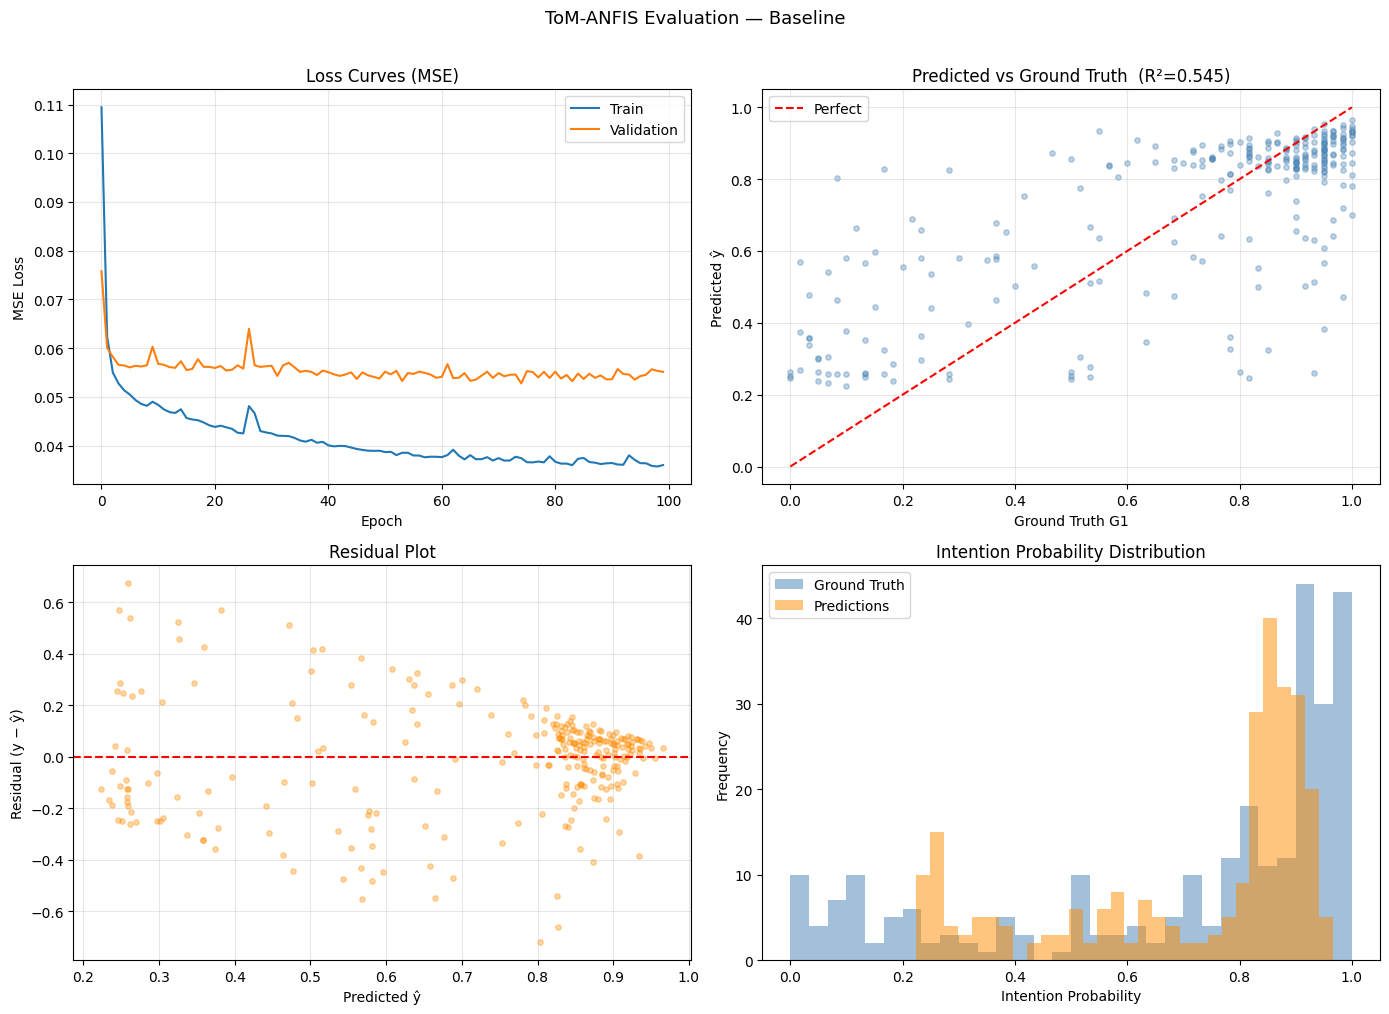

In [ ]:
# ── Collect all scenario results for the bar chart ────────────────────────────
all_scenarios = {
    'Path A\n(adult, green sig.)' : (result_A, '#2196F3'),
    'Path B\n(adult, green sig.)' : (result_B, '#42A5F5'),
    'Sc.1\n(child, red sig.)'     : (None,     '#F44336'),
    'Sc.2\n(senior, no sig.)'     : (None,     '#FF9800'),
    'Sc.3\n(adult, rushing)'      : (None,     '#4CAF50'),
}

sc1_feats = {f: scenarios['Scenario 1  —  Child · Red signal · Dense fast traffic'][f] for f in INPUT_ORDER}
sc2_feats = {f: scenarios['Scenario 2  —  Senior · No signal · Slow traffic'][f]        for f in INPUT_ORDER}
sc3_feats = {f: scenarios['Scenario 3  —  Adult rushing · Green signal · Stopped traffic'][f] for f in INPUT_ORDER}

for sc_feats, key in [(sc1_feats, 'Sc.1\n(child, red sig.)'),
                      (sc2_feats, 'Sc.2\n(senior, no sig.)'),
                      (sc3_feats, 'Sc.3\n(adult, rushing)')]:
    xr = np.array([[sc_feats[f] for f in INPUT_ORDER]], dtype=np.float32)
    xs = scaler.transform(xr)[0]
    all_scenarios[key] = (model.predict_explain(xs, threshold=0.0001),
                          all_scenarios[key][1])

labels = list(all_scenarios.keys())
probs  = [all_scenarios[k][0]['probability'] for k in labels]
colors = [all_scenarios[k][1] for k in labels]
levels = [all_scenarios[k][0]['intention_level'] for k in labels]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('ToM-ANFIS Inference — Prediction Summary', fontsize=14, fontweight='bold', y=1.01)

# ── Panel 1: scenario bar chart ───────────────────────────────────────────────
ax = axes[0]
bars = ax.bar(labels, probs, color=colors, edgecolor='white', linewidth=1.5, width=0.55)
ax.axhspan(0,    0.33, alpha=0.06, color='green',  label='LOW zone')
ax.axhspan(0.33, 0.67, alpha=0.06, color='orange', label='MEDIUM zone')
ax.axhspan(0.67, 1.0,  alpha=0.06, color='red',    label='HIGH zone')
ax.axhline(0.33, color='green',  ls='--', lw=1, alpha=0.5)
ax.axhline(0.67, color='red',    ls='--', lw=1, alpha=0.5)

for bar, prob, level in zip(bars, probs, levels):
    ax.text(bar.get_x() + bar.get_width()/2, prob + 0.015,
            f'{prob:.3f}\n{level}', ha='center', va='bottom', fontsize=9, fontweight='bold')

ax.set_ylim(0, 1.12)
ax.set_ylabel('Crossing Intention Probability', fontsize=11)
ax.set_title('Predicted Probabilities — All Scenarios', fontsize=11)
ax.legend(loc='upper right', fontsize=8)
ax.set_xlabel('Scenario', fontsize=11)
ax.tick_params(axis='x', labelsize=8.5)

# ── Panel 2: learned MFs for B3 (proximity) and A1 (vehicle awareness) ────────
ax2 = axes[1]
x_axis = np.linspace(0, 1, 300)

for feat_idx, feat_name, ls in [(2, 'B3 — Position Proximity', '-'),
                                  (5, 'A1 — Vehicle Awareness',  '--')]:
    centers = model.mf_layer.centers[feat_idx].detach().cpu().numpy()
    sigmas  = torch.abs(model.mf_layer.sigmas[feat_idx]).detach().cpu().numpy()
    mf_names = ['Low', 'Medium', 'High']
    colors_mf = ['#5C85D6', '#E07B39', '#5CAD6F']
    for j in range(3):
        mu = np.exp(-0.5 * ((x_axis - centers[j]) / sigmas[j]) ** 2)
        label = f'{feat_name[:2]} — {mf_names[j]}' if ls == '-' else None
        ax2.plot(x_axis, mu, ls=ls, lw=2, color=colors_mf[j], label=label, alpha=0.85)

ax2.set_title('Learned Gaussian MFs  (B3 solid · A1 dashed)', fontsize=11)
ax2.set_xlabel('Normalised Feature Value [0, 1]', fontsize=11)
ax2.set_ylabel('Membership Degree μ', fontsize=11)
ax2.legend(fontsize=9, loc='upper center', ncol=3)
ax2.set_xlim(0, 1)
ax2.set_ylim(0, 1.08)
ax2.grid(True, alpha=0.2)

plt.tight_layout()
plt.show()

---
## 10. Global Rule Analysis

Global rule importance ranks all 19,683 rules by their average absolute consequent weight.
Rules with high importance have learned to represent the most common or decisive pedestrian-crossing patterns across the entire training dataset.

This is a **model-level** explanation — it shows what the model has generalised, not what it concluded for a specific observation. Local per-prediction explanations are the fired rules shown in Sections 6 and 8.

In [ ]:
print('=' * 68)
print('GLOBAL RULE ANALYSIS — Top 10 Rules by Consequent Weight Importance')
print('=' * 68)

rules_global = model.global_rules(top_k=10)
for rank, (importance, rule_text) in enumerate(rules_global, 1):
    print(f'\n[Rule {rank:>2}]  importance = {importance:.4f}')
    # Split into antecedent and consequent for readable display
    if_part, _, then_part = rule_text.partition('\n   ')
    print(f'  {if_part}')
    print(f'   {then_part}')

════════════════════════════════════════════════════════════════════
GLOBAL RULE ANALYSIS — Top 10 Rules by Consequent Weight Importance
════════════════════════════════════════════════════════════════════

[Rule  1]  importance = 0.8103
  IF B1_age_vulnerability_awareness is Low AND B2_intersection_complexity is High AND B3_pedestrian_position_proximity is High AND B4_vehicle_density is Low AND G2_urgency_rushing is High AND A1_vehicle_awareness is Low AND A2_traffic_signal_awareness is Low AND C1_relative_vehicle_speed is Medium AND C2_occlusion_factor is Medium
   THEN intention = 0.651 + 1.505·B1_age_vulnerability_awareness + 0.800·B2_intersection_complexity + 0.548·B3_pedestrian_position_proximity + 1.032·B4_vehicle_density + 1.041·G2_urgency_rushing + 0.095·A1_vehicle_awareness + 0.941·A2_traffic_signal_awareness + 0.509·C1_relative_vehicle_speed + 0.980·C2_occlusion_factor

[Rule  2]  importance = 0.6539
  IF B1_age_vulnerability_awareness is Low AND B2_intersection_complexity i

---
## 11. Quick Reference

### Minimal Inference Snippet

```python
import torch, joblib, numpy as np, sys
from pathlib import Path
sys.path.insert(0, 'app')
from core.anfis import ANFIS

# Load
ckpt   = torch.load('app/artifacts/anfis_model_optimized.pth', map_location='cpu')
model  = ANFIS(len(ckpt['feature_names']), ckpt['num_mfs'], ckpt['feature_names'])
model.load_state_dict(ckpt['model_state_dict'])
model.eval()
scaler = joblib.load('app/artifacts/scaler_optimized.save')

# Predict  (B1, B2, B3, B4, G2, A1, A2, C1, C2)
x_raw    = np.array([[0.3, 0.6, 0.95, 0.17, 0.37, 0.73, 0.57, 0.23, 0.0]], dtype=np.float32)
x_scaled = scaler.transform(x_raw)[0]
result   = model.predict_explain(x_scaled, threshold=0.0001)

print(result['probability'])       # 0.8847
print(result['intention_level'])   # HIGH
print(result['fired_rules'][0])    # top rule dict
```

### Output Field Reference

| Field | Type | Description |
|-------|------|-------------|
| `probability` | `float` | Crossing intention score ∈ [0, 1] |
| `intention_level` | `str` | `LOW` (<0.33) / `MEDIUM` (0.33–0.67) / `HIGH` (>0.67) |
| `fired_rules` | `list[dict]` | Rules above threshold, sorted by `firing_strength` ↓ |
| `fired_rules[k]['rule_id']` | `int` | Index in [0, 19682] |
| `fired_rules[k]['firing_strength']` | `float` | Normalised weight $\bar{w}_k$ |
| `fired_rules[k]['rule']` | `str` | IF-THEN natural language string |
| `fired_rules[k]['consequent_value']` | `float` | Rule's TSK output after sigmoid |
| `fired_rules[k]['consequent_linguistic']` | `str` | LOW / MEDIUM / HIGH |

### Feature Encoding Reference

| Feature | Encoding |
|---------|----------|
| B1 Age | child=0.8, adult=0.3, middle-age=0.2, senior=0.7 |
| B2 Intersection | none=0.2, T-junction=0.5, 4-way=0.6, complex=0.6, highway=1.0 |
| B3 Proximity | 1 − (dist_to_crosswalk / 1920px); 0=far, 1=at edge |
| B4 Vehicle density | mean vehicles/frame ÷ 10, capped at 1.0 |
| G2 Urgency | average of walking_ratio and urgent_gesture_ratio |
| A1 Vehicle awareness | fraction of frames with PIE `look == 1` |
| A2 Signal awareness | mean signal safety score; −1.0 if no signal in scene |
| C1 Vehicle speed | mean OBD speed ÷ 27 m/s, capped at 1.0 |
| C2 Occlusion | mean PIE occlusion ÷ 2 |